# PrediCasa – Entregable II: Reducción de dimensión
**Modelos y Simulación de Sistemas II – Universidad de Antioquia**

Este notebook evalúa si es posible reducir la complejidad del modelo final. Parte de los resultados de `02_modelos.ipynb`, donde los dos mejores modelos (por RMSLE de validación) fueron **SVR (RBF)** y **ElasticNet**.

1. **Análisis individual de variables:** capacidad de cada variable para explicar el precio y variables candidatas a eliminar.
2. **Extracción lineal (PCA):** criterio para el número de componentes y nueva evaluación de los 2 mejores modelos.
3. **Extracción no lineal (UMAP):** criterio para el número de componentes y nueva evaluación de los 2 mejores modelos.
4. **Comparación final** de todas las variantes.

Se usan exactamente la misma partición, el mismo preprocesamiento, los mismos pliegues y las mismas métricas que en `02_modelos.ipynb`, para que los resultados sean comparables.

---
Configuración del entorno. Si el notebook se abre en Colab, se clona el repositorio para que `data/train.csv` se lea con la misma ruta que en GitHub; si ya se está dentro del repositorio, no hace nada. También se instala `umap-learn`, que no viene por defecto en Colab.

In [ ]:
import os, subprocess, sys

REPO_URL = "https://github.com/Felipemp20/Proyecto-Modelos-ll.git"
REPO_DIR = "Proyecto-Modelos-ll"

if not os.path.exists("data/train.csv"):
    if not os.path.exists(REPO_DIR):
        subprocess.run(["git", "clone", REPO_URL], check=True)
    os.chdir(REPO_DIR)

try:
    import umap
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "umap-learn"], check=True)

print("Directorio de trabajo:", os.getcwd())

Directorio de trabajo: /content/Proyecto-Modelos-ll


Importación de librerías y semilla (`SEED = 42`, la misma de `02_modelos.ipynb`).

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import joblib, tempfile, time, warnings

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.metrics import make_scorer, mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import ElasticNet
from sklearn.svm import SVR
from umap import UMAP

warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

SEED = 42
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

## 0. Datos, partición y preprocesamiento
Estos bloques repiten la preparación de `02_modelos.ipynb` (carga, eliminación de los atípicos Id 524 y 1299, partición 80/20 estratificada por deciles del precio). Con la misma semilla se obtienen exactamente las mismas 1166 viviendas de entrenamiento y 292 de test.

In [ ]:
df = pd.read_csv("data/train.csv", keep_default_na=False, na_values=["NA", ""])
atipicos = df[(df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)]
df = df.drop(index=atipicos.index).reset_index(drop=True)

y = df["SalePrice"]
X = df.drop(columns=["Id", "SalePrice"])

deciles = pd.qcut(y, q=10, labels=False)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=deciles, random_state=SEED)
print(f"Train: {X_train.shape[0]} viviendas | Test: {X_test.shape[0]} viviendas")

Train: 1166 viviendas | Test: 292 viviendas


Transformador `PreprocesadorAmes`, igual al de `02_modelos.ipynb` (NA = ausencia de la característica, `GarageYrBlt` sin garaje = `YearBuilt`, `LotFrontage` con la mediana por barrio aprendida en train, numéricas que son categóricas y codificación ordinal de las variables de calidad).

Se agrega un transformador nuevo, `EliminarColumnas`, para probar el efecto de quitar las variables candidatas que salgan del análisis individual.

In [ ]:
NONE_COLS = ["PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
             "GarageType", "GarageFinish", "GarageQual", "GarageCond",
             "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
             "MasVnrType"]
ZERO_COLS = ["GarageArea", "GarageCars", "MasVnrArea", "BsmtFinSF1", "BsmtFinSF2",
             "BsmtUnfSF", "TotalBsmtSF", "BsmtFullBath", "BsmtHalfBath"]
NUM_A_CAT = ["MSSubClass", "MoSold", "YrSold"]
ORD_COLS = ["ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC",
            "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond", "PoolQC"]
ESCALA = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}


class PreprocesadorAmes(BaseEstimator, TransformerMixin):
    def __init__(self, ordinal_como_entero=True):
        self.ordinal_como_entero = ordinal_como_entero

    def fit(self, X, y=None):
        self.mediana_barrio_ = X.groupby("Neighborhood")["LotFrontage"].median()
        self.mediana_lot_ = X["LotFrontage"].median()
        return self

    def transform(self, X):
        X = X.copy()
        for c in NONE_COLS:
            X[c] = X[c].fillna("None")
        for c in ZERO_COLS:
            X[c] = X[c].fillna(0)
        X["GarageYrBlt"] = X["GarageYrBlt"].fillna(X["YearBuilt"])
        X["LotFrontage"] = (X["LotFrontage"]
                            .fillna(X["Neighborhood"].map(self.mediana_barrio_))
                            .fillna(self.mediana_lot_))
        for c in NUM_A_CAT:
            X[c] = X[c].astype(str)
        if self.ordinal_como_entero:
            for c in ORD_COLS:
                X[c] = X[c].map(ESCALA).astype(float)
        return X


class EliminarColumnas(BaseEstimator, TransformerMixin):
    def __init__(self, columnas=()):
        self.columnas = columnas

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return X.drop(columns=list(self.columnas))

Función `crear_pipeline`, ahora con dos opciones más:
- `eliminar`: lista de variables que se quitan antes de codificar.
- `reductor`: un paso de reducción de dimensión (PCA o UMAP) que se aplica **después** de la codificación y el escalado, y **antes** del modelo. Como está dentro del pipeline, PCA y UMAP se ajustan solo con los pliegues de entrenamiento (sin fuga de información).

`memoria` guarda en caché los pasos ya ajustados. UMAP es lento, y sin caché se volvería a calcular para cada combinación de hiperparámetros del modelo aunque los datos del pliegue sean los mismos.

In [ ]:
CACHE = joblib.Memory(location=tempfile.mkdtemp(), verbose=0)


def crear_pipeline(modelo, escalar=True, ordinal_como_entero=True, eliminar=(), reductor=None):
    paso_num = [("imp", SimpleImputer(strategy="median"))]
    if escalar:
        paso_num.append(("esc", StandardScaler()))
    columnas = ColumnTransformer([
        ("num", Pipeline(paso_num), make_column_selector(dtype_include="number")),
        ("cat", Pipeline([
            ("imp", SimpleImputer(strategy="most_frequent")),
            ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), make_column_selector(dtype_include="object")),
    ])
    transf_y = Pipeline([
        ("log", FunctionTransformer(np.log1p, inverse_func=np.expm1, check_inverse=False)),
        ("esc", StandardScaler()),
    ])
    pasos = [("prep", PreprocesadorAmes(ordinal_como_entero=ordinal_como_entero)),
             ("eliminar", EliminarColumnas(tuple(eliminar))),
             ("cols", columnas)]
    if reductor is not None:
        pasos.append(("red", reductor))
    pasos.append(("modelo", TransformedTargetRegressor(regressor=modelo, transformer=transf_y)))
    return Pipeline(pasos, memory=CACHE if reductor is not None else None)

Métricas e intervalos de confianza, iguales a los de `02_modelos.ipynb`:
- **RMSLE** (principal), **RMSE** y **MAE** en dólares y **R²**.
- Validación cruzada de 5 pliegues con la misma semilla. Intervalo del 95 % con la t de Student para entrenamiento y validación, y con bootstrap (1000 remuestreos) para test.

In [ ]:
def rmsle(y_true, y_pred):
    y_pred = np.maximum(y_pred, 0)
    return np.sqrt(np.mean((np.log1p(y_pred) - np.log1p(y_true)) ** 2))

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

FUNCIONES = {"RMSLE": rmsle, "RMSE": rmse, "MAE": mean_absolute_error, "R2": r2_score}
SCORERS = {m: make_scorer(f, greater_is_better=(m == "R2")) for m, f in FUNCIONES.items()}
METRICAS = list(FUNCIONES)
CV = KFold(n_splits=5, shuffle=True, random_state=SEED)


def intervalo(valores, conf=0.95):
    valores = np.asarray(valores)
    k = len(valores)
    return valores.mean(), stats.t.ppf((1 + conf) / 2, k - 1) * valores.std(ddof=1) / np.sqrt(k)

Función `evaluar(...)`: hace la búsqueda en malla (si se le da una malla) con los 5 pliegues, toma la mejor configuración, la reentrena con todo train y la evalúa en test. Devuelve una fila con todas las métricas en train, validación y test (media ± intervalo) y el número de dimensiones que recibe el modelo. Los resultados se guardan en `results/` para no repetir el cálculo.

In [ ]:
RECALCULAR = False


def N_JOBS(pipe):
    # Con caché (PCA/UMAP) se trabaja en un solo proceso: la caché se comparte entre
    # combinaciones y los procesos paralelos no pueden usar las clases definidas en el notebook.
    return 1 if pipe.memory is not None else -1


def n_dimensiones(pipe):
    # Número de columnas que recibe el modelo (después de codificar y, si aplica, reducir)
    Xt = pipe[:-1].transform(X_train.head(5))
    return Xt.shape[1]


def evaluar(clave, nombre, pipe, malla=None):
    ruta = f"results/red_{clave}.pkl"
    if not RECALCULAR and os.path.exists(ruta):
        guardado = joblib.load(ruta)
        print(f"[{clave}] cargado de {ruta}")
        return guardado["fila"], guardado["res"]

    t0 = time.time()
    gs = GridSearchCV(pipe, malla or {}, cv=CV, scoring=SCORERS, refit="RMSLE",
                      return_train_score=True, n_jobs=N_JOBS(pipe))
    gs.fit(X_train, y_train)
    res = pd.DataFrame(gs.cv_results_)
    i = gs.best_index_

    fila = {"variante": nombre}
    for m in METRICAS:
        signo = 1 if m == "R2" else -1
        for fase, pref in [("train", "train"), ("val", "test")]:
            vals = [signo * res.loc[i, f"split{k}_{pref}_{m}"] for k in range(CV.n_splits)]
            fila[f"{m}_{fase}"], fila[f"{m}_{fase}_IC"] = intervalo(vals)

    pred = gs.best_estimator_.predict(X_test)
    real = y_test.to_numpy()
    rng = np.random.default_rng(SEED)
    for m, f in FUNCIONES.items():
        boot = [f(real[j], pred[j]) for j in (rng.integers(0, len(real), len(real)) for _ in range(1000))]
        fila[f"{m}_test"], fila[f"{m}_test_IC"] = f(real, pred), 1.96 * np.std(boot)

    fila["dimensiones"] = n_dimensiones(gs.best_estimator_)
    fila["mejores_hiperparametros"] = {k.split("__")[-1]: v for k, v in gs.best_params_.items()}
    joblib.dump({"fila": fila, "res": res}, ruta)
    print(f"[{clave}] {len(res)} combinaciones en {(time.time() - t0) / 60:.1f} min")
    return fila, res


def tabla(filas):
    t = pd.DataFrame(filas).set_index("variante")
    salida = pd.DataFrame(index=t.index)
    salida["Dimensiones"] = t["dimensiones"]
    if "DIM_BASE" in globals():  # reducción respecto a las dimensiones originales de cada modelo
        base = [DIM_BASE[v.split(" – ")[0]] for v in t.index]
        salida["Reducción"] = [f"{100 * (1 - d / b):.1f} %" for d, b in zip(t["dimensiones"], base)]
    formatos = {"RMSLE": "{:.4f}", "RMSE": "{:,.0f}", "MAE": "{:,.0f}", "R2": "{:.3f}"}
    for m, f in formatos.items():
        for fase in ["train", "val", "test"]:
            salida[f"{m} {fase}"] = [f"{f.format(a)} ± {f.format(b)}"
                                     for a, b in zip(t[f"{m}_{fase}"], t[f"{m}_{fase}_IC"])]
    return salida


def guardar(nombre):
    plt.tight_layout()
    plt.savefig(f"figures/{nombre}.png", dpi=200, bbox_inches="tight")
    plt.show()

Definición de los **dos mejores modelos** de `02_modelos.ipynb`, con los hiperparámetros que obtuvieron en la búsqueda en malla:

| Modelo | Hiperparámetros | RMSLE validación |
|---|---|---|
| SVR (RBF) | C = 100, gamma = 0.0001, epsilon = 0.1 | 0.1147 |
| ElasticNet | alpha = 0.003, l1_ratio = 0.5, ordinales en one-hot | 0.1153 |

Como PCA y UMAP cambian las columnas que recibe el modelo (otra escala y otro número), los hiperparámetros óptimos pueden cambiar. Por eso, al reducir la dimensión, se repite una **búsqueda en malla pequeña** alrededor de los valores originales (`MALLA_RED` y `MALLA_RED_UMAP`). La función `curva_componentes` hace esa búsqueda para cada número de componentes y guarda la mejor combinación de cada uno.

Primero se recalcula su desempeño **sin reducción**, que es la referencia contra la que se comparan todas las variantes.

In [ ]:
MODELOS = {
    "SVR": dict(modelo=lambda: SVR(kernel="rbf", C=100, gamma=0.0001, epsilon=0.1),
                ordinal_como_entero=True),
    "ElasticNet": dict(modelo=lambda: ElasticNet(alpha=0.003, l1_ratio=0.5, max_iter=20000),
                       ordinal_como_entero=False),
}

def pipe_de(nombre, **kw):
    cfg = MODELOS[nombre]
    return crear_pipeline(cfg["modelo"](), ordinal_como_entero=cfg["ordinal_como_entero"], **kw)

MALLA_RED = {
    "SVR": {"modelo__regressor__C": [10, 100, 1000],
            "modelo__regressor__gamma": [0.0001, 0.001, 0.01, "scale"]},
    "ElasticNet": {"modelo__regressor__alpha": [0.001, 0.003, 0.01, 0.03, 0.1],
                   "modelo__regressor__l1_ratio": [0.1, 0.5, 1.0]},
}

MALLA_RED_UMAP = {
    "SVR": {"modelo__regressor__C": [1, 10, 100, 1000],
            "modelo__regressor__gamma": [0.001, 0.01, 0.1, "scale"]},
    "ElasticNet": MALLA_RED["ElasticNet"],
}


def curva_componentes(clave, m, reductor, ks, malla):
    # Para cada número de componentes k se ajustan los hiperparámetros del modelo (malla pequeña)
    # y se guarda la mejor combinación. Así cada k se compara en igualdad de condiciones.
    ruta = f"results/red_curva_{clave}.pkl"
    if not RECALCULAR and os.path.exists(ruta):
        return pd.read_pickle(ruta)
    pipe = pipe_de(m, reductor=reductor)
    gs = GridSearchCV(pipe, {"red__n_components": ks, **malla}, cv=CV, scoring=SCORERS,
                      refit=False, return_train_score=True, n_jobs=1).fit(X_train, y_train)
    r = pd.DataFrame(gs.cv_results_)
    r["k"] = r["param_red__n_components"].astype(int)
    mejor = r.loc[r.groupby("k")["mean_test_RMSLE"].idxmax()]   # max de -RMSLE = mejor
    d = pd.DataFrame({"modelo": m, "k": mejor["k"].to_numpy(),
                      "train": -mejor["mean_train_RMSLE"].to_numpy(),
                      "val": -mejor["mean_test_RMSLE"].to_numpy(),
                      "val_std": mejor["std_test_RMSLE"].to_numpy()})
    d.to_pickle(ruta)
    return d

FILAS = {"SVR": [], "ElasticNet": []}
for m in MODELOS:
    fila, _ = evaluar(f"{m.lower()}_original", f"{m} – original", pipe_de(m))
    FILAS[m].append(fila)

DIM_BASE = {m: FILAS[m][0]["dimensiones"] for m in MODELOS}
print("Dimensiones sin reducción:", DIM_BASE)
tabla(FILAS["SVR"] + FILAS["ElasticNet"])[["Dimensiones", "RMSLE train", "RMSLE val", "RMSLE test", "R2 test"]]

[svr_original] 1 combinaciones en 0.1 min
[elasticnet_original] 1 combinaciones en 0.1 min
Dimensiones sin reducción: {'SVR': 287, 'ElasticNet': 326}


,Dimensiones,RMSLE train,RMSLE val,RMSLE test,R2 test
variante,,,,,
SVR – original,287,0.0992 ± 0.0052,0.1147 ± 0.0211,0.1111 ± 0.0169,0.937 ± 0.019
ElasticNet – original,326,0.0971 ± 0.0034,0.1153 ± 0.0157,0.1099 ± 0.0135,0.934 ± 0.021


## 1. Análisis individual de variables
Se mide la capacidad de cada una de las 79 variables para explicar el precio, **por separado** y usando **solo los datos de entrenamiento** (para no usar información de test). Como la variable objetivo es continua, se usan medidas de correlación:

- **Variables numéricas y ordinales:** correlación de **Spearman** ($\rho$) con $\log(1 + \text{SalePrice})$. Se usa Spearman en lugar de Pearson porque mide cualquier relación monótona (no solo lineal) y es menos sensible a valores atípicos.
- **Variables nominales:** **razón de correlación** $\eta$, que mide qué parte de la variación del precio se explica por la categoría:
$\eta^2 = \frac{\sum_k n_k(\bar{y}_k - \bar{y})^2}{\sum_i (y_i - \bar{y})^2}$, donde $\bar{y}_k$ es el precio medio (en logaritmo) de la categoría $k$. Va de 0 (la categoría no dice nada del precio) a 1.

Así, $|\rho|$ y $\eta$ quedan en la misma escala (0 a 1) y se pueden comparar.

La preparación aplica las mismas reglas del dominio del preprocesamiento (NA = ausencia, ordinales como enteros), sin codificar en one-hot, para analizar cada variable original.

In [ ]:
prep_analisis = PreprocesadorAmes(ordinal_como_entero=True).fit(X_train)
D = prep_analisis.transform(X_train)
log_y = np.log1p(y_train)

filas = []
for c in D.columns:
    if pd.api.types.is_numeric_dtype(D[c]):
        rho = D[c].corr(log_y, method="spearman")
        filas.append({"variable": c, "tipo": "ordinal" if c in ORD_COLS else "numérica",
                      "medida": "Spearman ρ", "valor": rho, "relevancia": abs(rho)})
    else:
        s = D[c].fillna("None")
        g = log_y.groupby(s)
        eta2 = (g.count() * (g.mean() - log_y.mean()) ** 2).sum() / ((log_y - log_y.mean()) ** 2).sum()
        filas.append({"variable": c, "tipo": "nominal", "medida": "η (razón de correlación)",
                      "valor": np.sqrt(eta2), "relevancia": np.sqrt(eta2)})

relevancia = pd.DataFrame(filas).sort_values("relevancia", ascending=False).reset_index(drop=True)
relevancia["categoría dominante (%)"] = [100 * D[v].value_counts(normalize=True, dropna=False).iloc[0]
                                         for v in relevancia["variable"]]
relevancia.to_csv("results/relevancia_variables.csv", index=False)
relevancia.round(3).head(15)

,variable,tipo,medida,valor,relevancia,categoría dominante (%)
0,OverallQual,numérica,Spearman ρ,0.815,0.815,26.501
1,Neighborhood,nominal,η (razón de correlación),0.764,0.764,15.009
2,GrLivArea,numérica,Spearman ρ,0.721,0.721,1.201
3,ExterQual,ordinal,Spearman ρ,0.686,0.686,62.093
4,BsmtQual,ordinal,Spearman ρ,0.680,0.680,44.597
5,GarageCars,numérica,Spearman ρ,0.678,0.678,57.633
6,KitchenQual,ordinal,Spearman ρ,0.675,0.675,50.772
7,YearBuilt,numérica,Spearman ρ,0.644,0.644,4.631
8,GarageArea,numérica,Spearman ρ,0.633,0.633,5.403
9,FullBath,numérica,Spearman ρ,0.619,0.619,52.487


Gráfica de las 20 variables más relevantes y las 20 menos relevantes. El color indica el tipo de medida (Spearman para numéricas y ordinales, η para nominales).

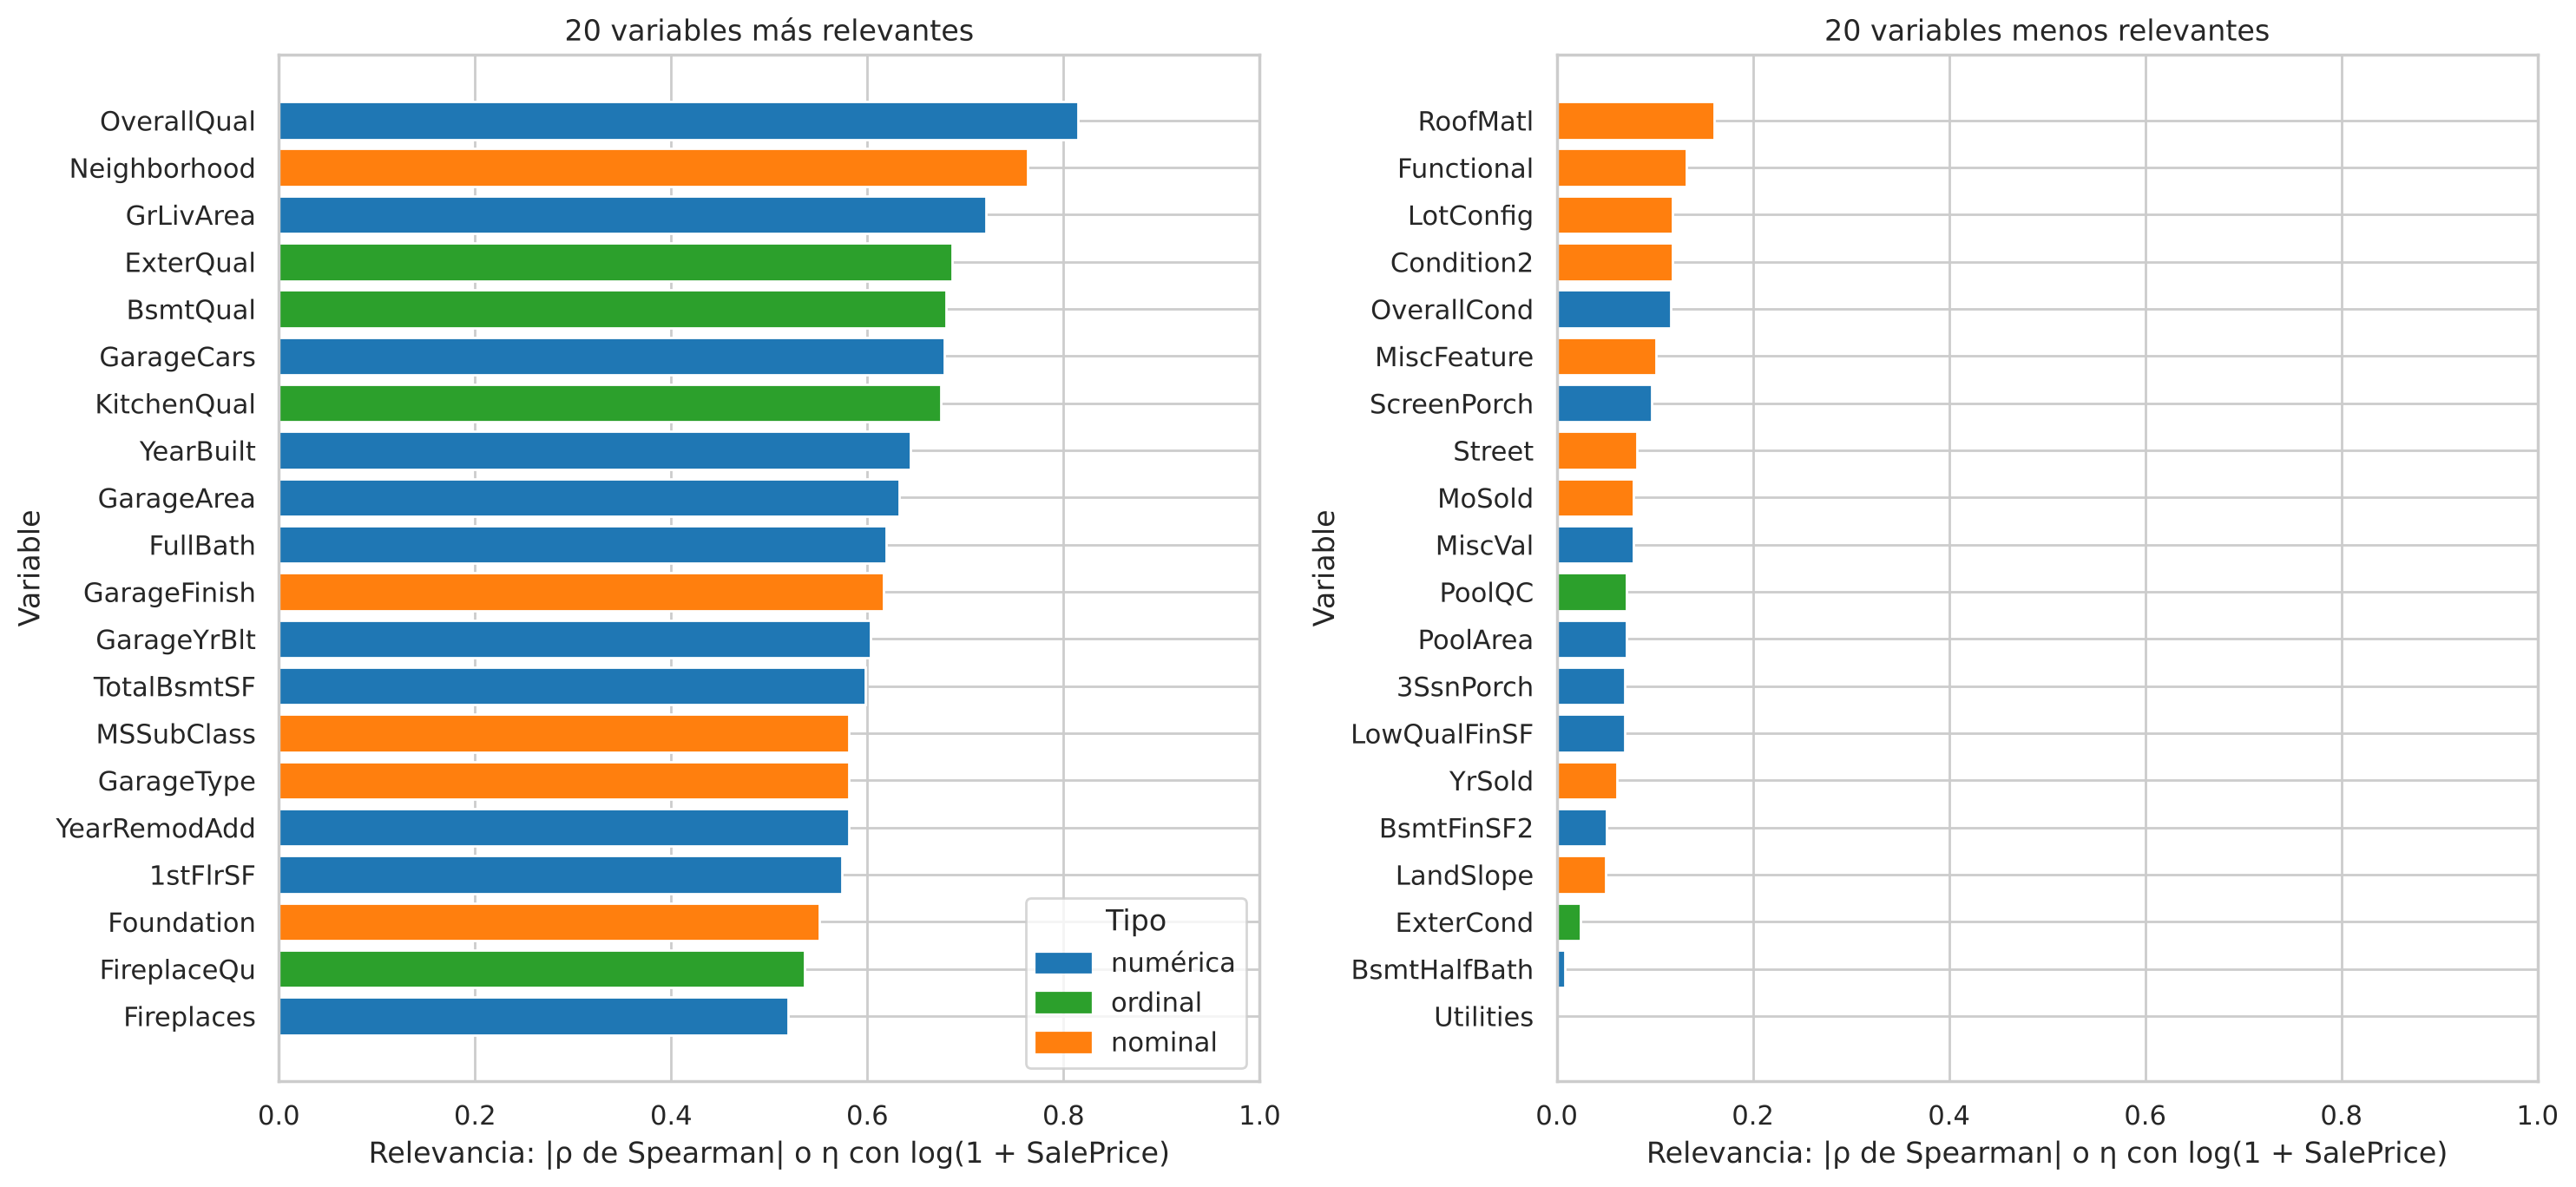

In [ ]:
colores = {"numérica": "tab:blue", "ordinal": "tab:green", "nominal": "tab:orange"}
fig, ax = plt.subplots(1, 2, figsize=(15, 7))
for a, datos, titulo in [(ax[0], relevancia.head(20), "20 variables más relevantes"),
                         (ax[1], relevancia.tail(20), "20 variables menos relevantes")]:
    a.barh(datos["variable"], datos["relevancia"], color=datos["tipo"].map(colores))
    a.invert_yaxis()
    a.set_xlabel("Relevancia: |ρ de Spearman| o η con log(1 + SalePrice)")
    a.set_ylabel("Variable")
    a.set_title(titulo)
    a.set_xlim(0, 1)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colores.values()]
ax[0].legend(handles, colores.keys(), title="Tipo")
guardar("15_relevancia_variables")

Además de la relevancia individual, se revisa la **redundancia**: pares de variables numéricas u ordinales con $|\rho| > 0.8$ entre sí aportan casi la misma información (multicolinealidad). En cada par, la candidata a eliminar es la que tiene **menor** relevancia con el precio.

In [ ]:
num_cols = [c for c in D.columns if pd.api.types.is_numeric_dtype(D[c])]
corr = D[num_cols].corr(method="spearman").abs()
pares = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
             .loc[lambda s: s > 0.8].sort_values(ascending=False))
rel = relevancia.set_index("variable")["relevancia"]

redundancia = pd.DataFrame([
    {"variable A": a, "variable B": b, "|ρ| entre ellas": r,
     "relevancia A": rel[a], "relevancia B": rel[b],
     "candidata a eliminar": a if rel[a] < rel[b] else b}
    for (a, b), r in pares.items()])
redundancia.round(3)

,variable A,variable B,|ρ| entre ellas,relevancia A,relevancia B,candidata a eliminar
0,PoolArea,PoolQC,1.000,0.071,0.071,PoolArea
1,YearBuilt,GarageYrBlt,0.896,0.644,0.603,GarageYrBlt
2,Fireplaces,FireplaceQu,0.895,0.519,0.536,Fireplaces
3,GarageCars,GarageArea,0.849,0.678,0.633,GarageArea
4,TotalBsmtSF,1stFlrSF,0.824,0.598,0.574,1stFlrSF
5,GrLivArea,TotRmsAbvGrd,0.819,0.721,0.509,TotRmsAbvGrd
6,GarageQual,GarageCond,0.814,0.351,0.335,GarageCond


**Criterios para elegir las variables candidatas a eliminar:**
1. **Baja relevancia:** $|\rho| < 0.1$ o $\eta < 0.1$ (explican menos del 1 % de la variación del precio por sí solas).
2. **Casi constantes:** una sola categoría o valor ocupa más del 99 % de las viviendas.
3. **Redundantes:** la menos relevante de cada par con $|\rho| > 0.8$.

Que una variable tenga baja relevancia individual no significa que sea inútil: puede aportar en combinación con otras (por ejemplo, `OverallCond` cambia de significado según la antigüedad de la vivienda). Por eso, después de identificarlas, se comprueba con los dos modelos si quitarlas mejora o empeora el desempeño.

In [ ]:
baja = set(relevancia.loc[relevancia["relevancia"] < 0.1, "variable"])
constantes = set(relevancia.loc[relevancia["categoría dominante (%)"] > 99, "variable"])
redundantes = set(redundancia["candidata a eliminar"])
CANDIDATAS = sorted(baja | constantes | redundantes)

motivo = pd.DataFrame({
    "variable": CANDIDATAS,
    "baja relevancia": [v in baja for v in CANDIDATAS],
    "casi constante": [v in constantes for v in CANDIDATAS],
    "redundante": [v in redundantes for v in CANDIDATAS],
    "relevancia": [rel[v] for v in CANDIDATAS],
}).sort_values("relevancia")
motivo.to_csv("results/variables_candidatas.csv", index=False)
print(f"{len(CANDIDATAS)} variables candidatas a eliminar de {D.shape[1]}")
motivo.round(3)

21 variables candidatas a eliminar de 79


,variable,baja relevancia,casi constante,redundante,relevancia
19,Utilities,True,True,False,0.000
3,BsmtHalfBath,True,False,False,0.008
5,ExterCond,True,False,False,0.024
10,LandSlope,True,False,False,0.050
2,BsmtFinSF2,True,False,False,0.051
20,YrSold,True,False,False,0.062
11,LowQualFinSF,True,False,False,0.069
1,3SsnPorch,True,False,False,0.069
14,PoolArea,True,True,True,0.071
15,PoolQC,True,True,False,0.071


Nueva evaluación de los dos modelos **sin las variables candidatas** (con los mismos hiperparámetros). Si el RMSLE de validación no empeora, esas variables no aportan y se pueden quitar para simplificar el modelo.

In [ ]:
for m in MODELOS:
    fila, _ = evaluar(f"{m.lower()}_seleccion", f"{m} – sin candidatas", pipe_de(m, eliminar=CANDIDATAS))
    FILAS[m].append(fila)

tabla([FILAS[m][i] for m in MODELOS for i in (0, 1)])[
    ["Dimensiones", "Reducción", "RMSLE train", "RMSLE val", "RMSLE test", "R2 test"]]

[svr_seleccion] cargado de results/red_svr_seleccion.pkl
[elasticnet_seleccion] cargado de results/red_elasticnet_seleccion.pkl


,Dimensiones,Reducción,RMSLE train,RMSLE val,RMSLE test,R2 test
variante,,,,,,
SVR – original,287,0.0 %,0.0992 ± 0.0052,0.1147 ± 0.0211,0.1111 ± 0.0169,0.937 ± 0.019
SVR – sin candidatas,242,15.7 %,0.1026 ± 0.0051,0.1140 ± 0.0203,0.1129 ± 0.0164,0.932 ± 0.021
ElasticNet – original,326,0.0 %,0.0971 ± 0.0034,0.1153 ± 0.0157,0.1099 ± 0.0135,0.934 ± 0.021
ElasticNet – sin candidatas,269,17.5 %,0.0997 ± 0.0033,0.1146 ± 0.0171,0.1102 ± 0.0132,0.932 ± 0.022


## 2. Extracción de características lineal: PCA
PCA transforma las columnas (ya codificadas y escaladas) en **componentes principales**: combinaciones lineales no correlacionadas entre sí, ordenadas de mayor a menor varianza explicada. Quedarse con las primeras $k$ componentes reduce la dimensión conservando la mayor parte de la información.

**Criterio para el número de componentes:** el menor $k$ que explica al menos el **95 % de la varianza acumulada**. Es un criterio habitual que conserva casi toda la información de los datos y no depende del modelo ni de la variable objetivo (no usa `SalePrice`, así que no hay riesgo de sobreajustar la elección).

Primero se calcula la varianza explicada con los datos de entrenamiento.

In [ ]:
# Cada modelo tiene su propia codificación (ElasticNet usa las ordinales en one-hot),
# así que la varianza explicada se calcula por separado.
XC, VAR_ACUM, K_PCA = {}, {}, {}
for m in MODELOS:
    XC[m] = pipe_de(m)[:-1].fit(X_train).transform(X_train)   # prep + eliminar + cols (sin el modelo)
    VAR_ACUM[m] = np.cumsum(PCA(random_state=SEED).fit(XC[m]).explained_variance_ratio_)
    K_PCA[m] = int(np.searchsorted(VAR_ACUM[m], 0.95) + 1)
    print(f"{m}: {K_PCA[m]} componentes para el 95 % de varianza, de {XC[m].shape[1]} columnas "
          f"(reducción del {100 * (1 - K_PCA[m] / XC[m].shape[1]):.1f} %)")
    for umbral in [0.80, 0.90, 0.95, 0.99]:
        print(f"    {int(umbral * 100)} % de varianza -> {int(np.searchsorted(VAR_ACUM[m], umbral) + 1)} componentes")

SVR: 80 componentes para el 95 % de varianza, de 287 columnas (reducción del 72.1 %)
    80 % de varianza -> 30 componentes
    90 % de varianza -> 55 componentes
    95 % de varianza -> 80 componentes
    99 % de varianza -> 136 componentes
ElasticNet: 92 componentes para el 95 % de varianza, de 326 columnas (reducción del 71.8 %)
    80 % de varianza -> 35 componentes
    90 % de varianza -> 63 componentes
    95 % de varianza -> 92 componentes
    99 % de varianza -> 154 componentes


Gráfica de la varianza explicada acumulada para la codificación de cada modelo, con la línea del 95 % y el número de componentes elegido.

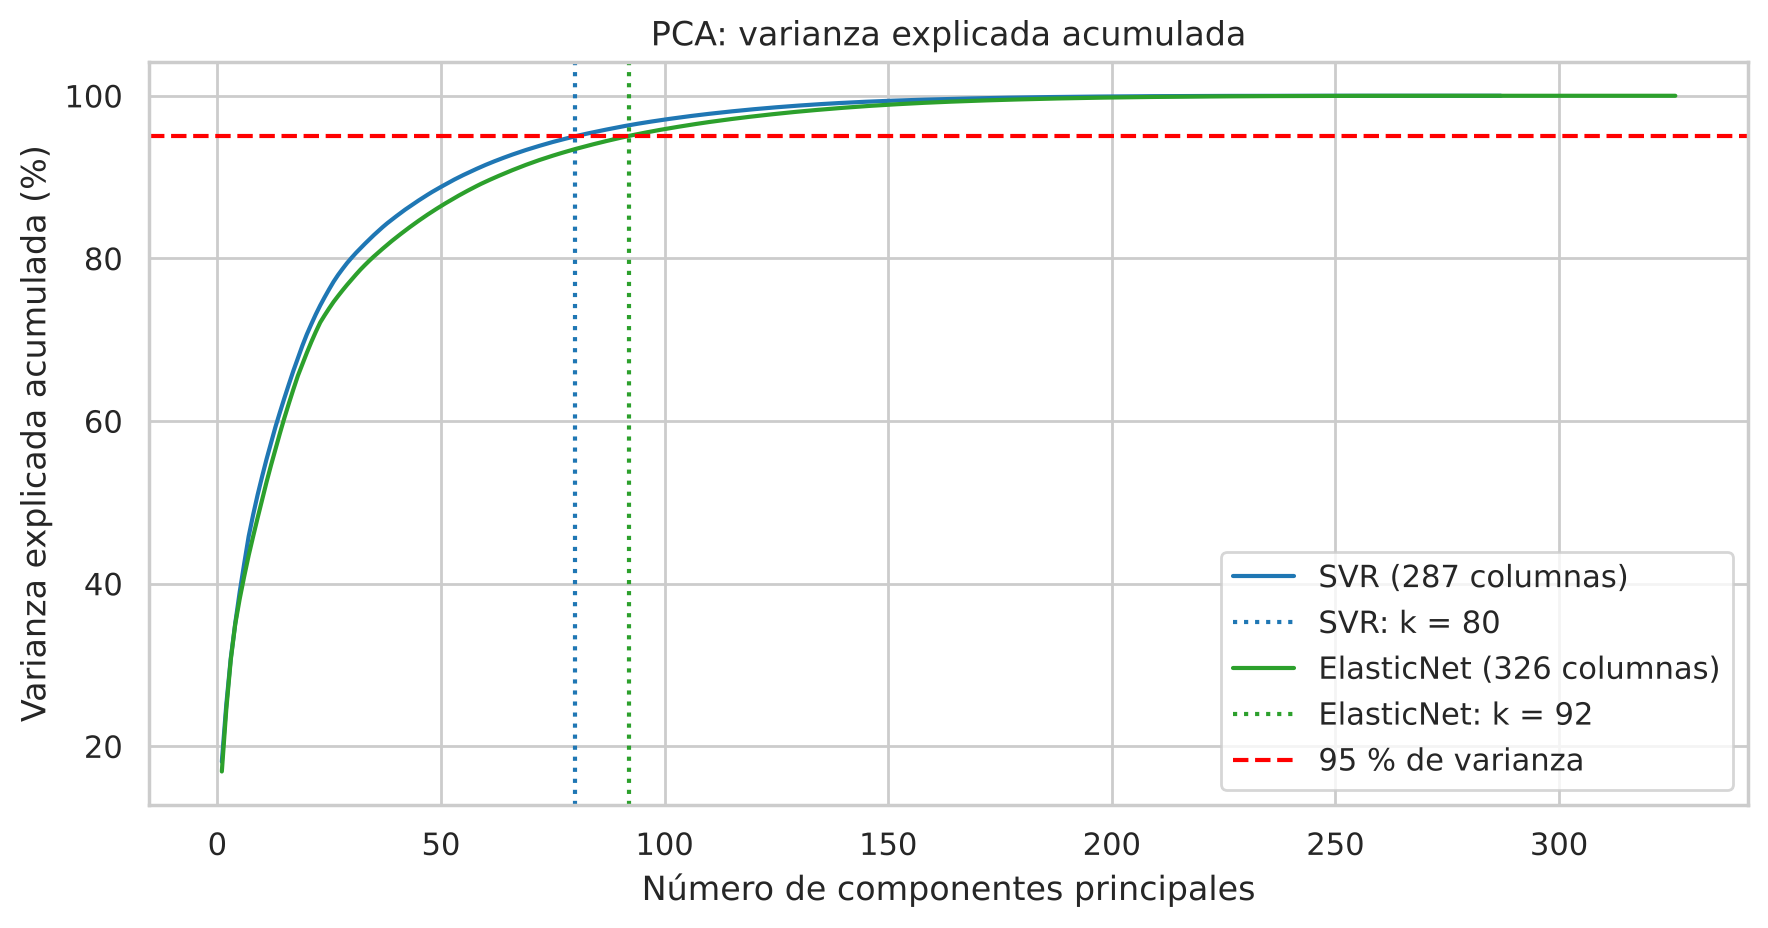

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.8))
for m, color in zip(MODELOS, ["tab:blue", "tab:green"]):
    v = VAR_ACUM[m]
    ax.plot(np.arange(1, len(v) + 1), 100 * v, color=color, label=f"{m} ({len(v)} columnas)")
    ax.axvline(K_PCA[m], color=color, ls=":", label=f"{m}: k = {K_PCA[m]}")
ax.axhline(95, color="red", ls="--", label="95 % de varianza")
ax.set_xlabel("Número de componentes principales")
ax.set_ylabel("Varianza explicada acumulada (%)")
ax.set_title("PCA: varianza explicada acumulada")
ax.legend()
guardar("16_pca_varianza")

Para comprobar el criterio, se evalúan los dos modelos con distintos números de componentes (ajustando sus hiperparámetros para cada uno) y se grafica el RMSLE de entrenamiento y validación. Así se ve cuánto desempeño se pierde al reducir.

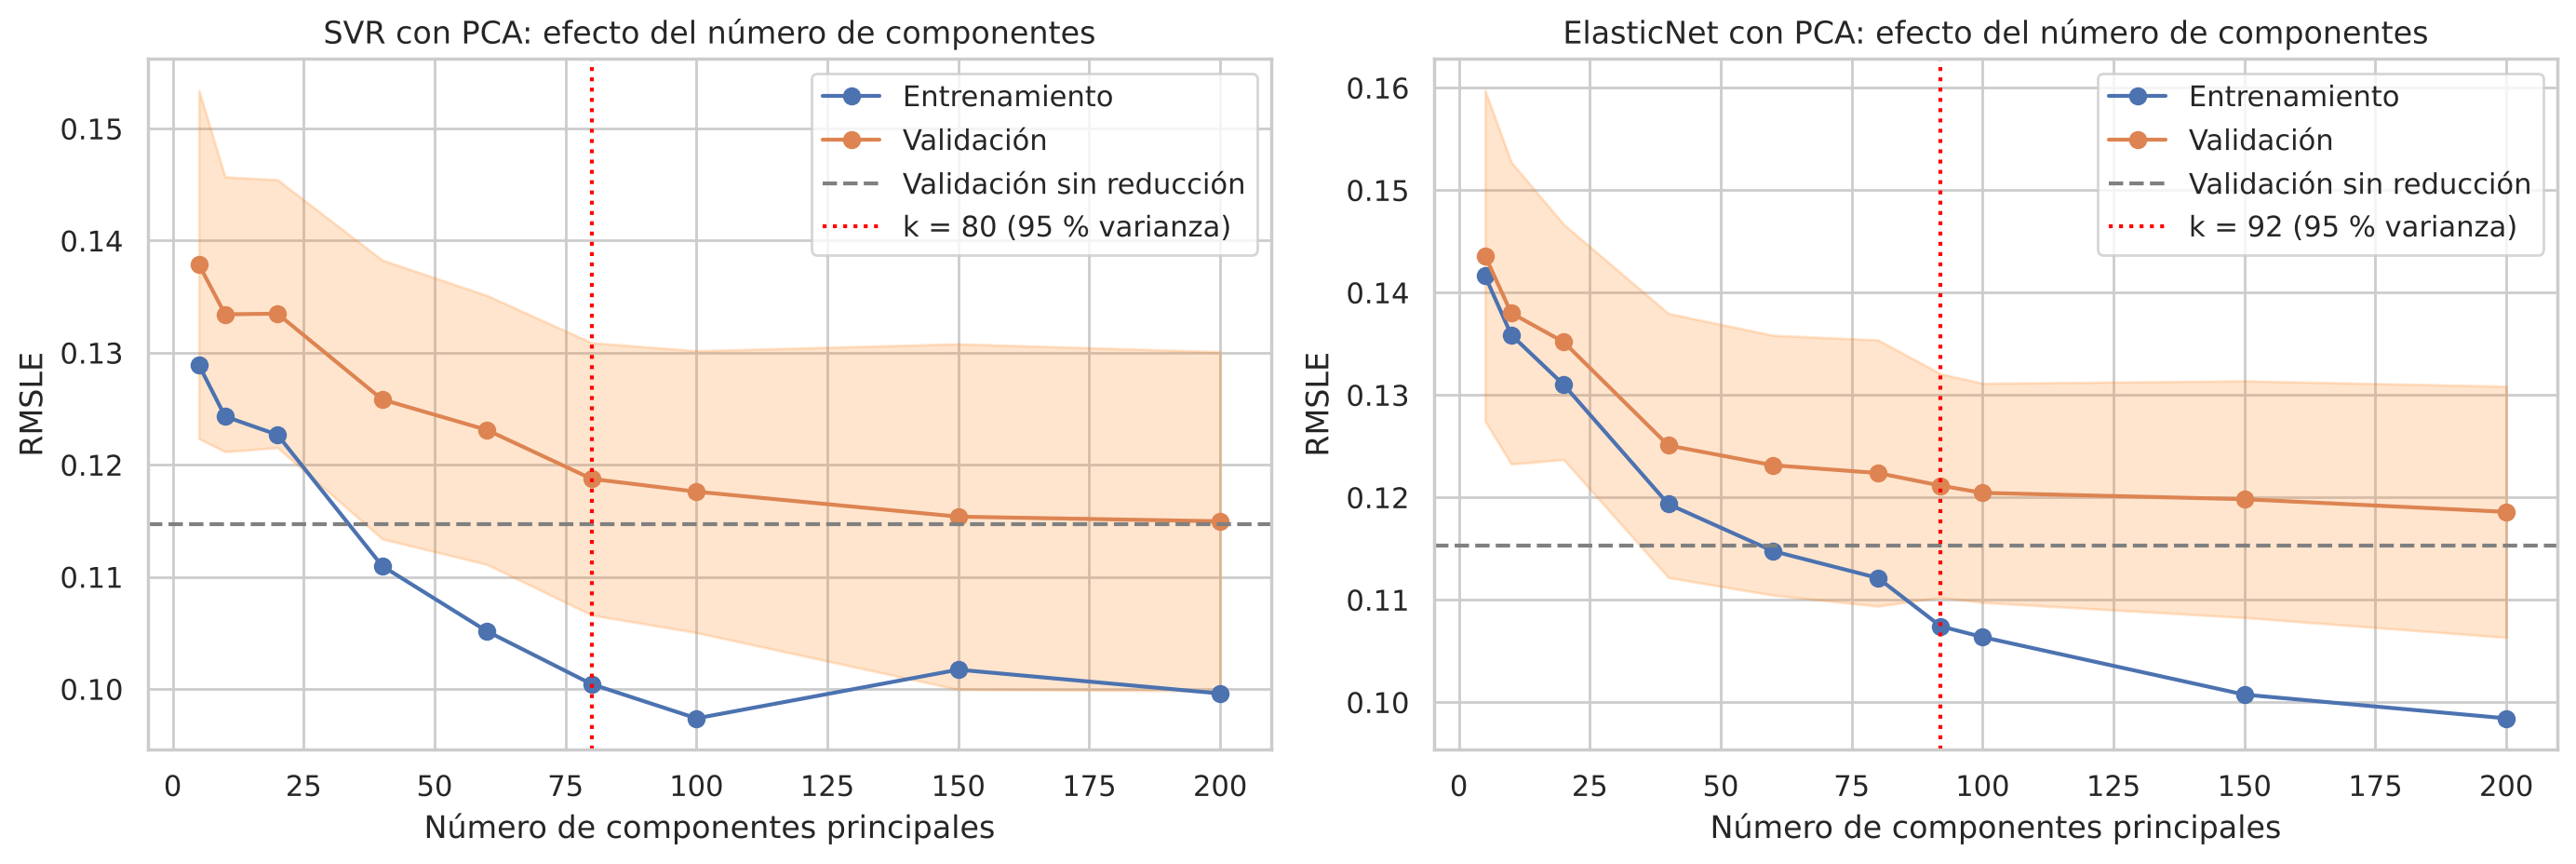

In [ ]:
curva_pca = pd.concat([
    curva_componentes(f"pca_{m.lower()}", m, PCA(random_state=SEED),
                      sorted(set([5, 10, 20, 40, 60, 80, 100, 150, 200, K_PCA[m]])), MALLA_RED[m])
    for m in MODELOS], ignore_index=True)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for a, m in zip(ax, MODELOS):
    d = curva_pca[curva_pca["modelo"] == m]
    a.plot(d["k"], d["train"], "o-", label="Entrenamiento")
    a.plot(d["k"], d["val"], "o-", label="Validación")
    a.fill_between(d["k"], d["val"] - d["val_std"], d["val"] + d["val_std"], color="tab:orange", alpha=0.2)
    a.axhline(FILAS[m][0]["RMSLE_val"], color="gray", ls="--", label="Validación sin reducción")
    a.axvline(K_PCA[m], color="red", ls=":", label=f"k = {K_PCA[m]} (95 % varianza)")
    a.set_xlabel("Número de componentes principales")
    a.set_ylabel("RMSLE")
    a.set_title(f"{m} con PCA: efecto del número de componentes")
    a.legend()
guardar("17_pca_componentes")

Nueva evaluación de los dos modelos con las **$k$ componentes elegidas** (con la búsqueda en malla pequeña de hiperparámetros), incluyendo test.

In [ ]:
for m in MODELOS:
    fila, _ = evaluar(f"{m.lower()}_pca", f"{m} – PCA ({K_PCA[m]} comp.)",
                      pipe_de(m, reductor=PCA(n_components=K_PCA[m], random_state=SEED)), MALLA_RED[m])
    FILAS[m].append(fila)
    print(f"  {m}: mejores hiperparámetros con PCA -> {fila['mejores_hiperparametros']}")

tabla([FILAS[m][i] for m in MODELOS for i in (0, 2)])

[svr_pca] cargado de results/red_svr_pca.pkl
  SVR: mejores hiperparámetros con PCA -> {'C': 10, 'gamma': 0.001}
[elasticnet_pca] cargado de results/red_elasticnet_pca.pkl
  ElasticNet: mejores hiperparámetros con PCA -> {'alpha': 0.01, 'l1_ratio': 0.1}


,Dimensiones,Reducción,RMSLE train,RMSLE val,RMSLE test,RMSE train,RMSE val,RMSE test,MAE train,MAE val,MAE test,R2 train,R2 val,R2 test
variante,,,,,,,,,,,,,,
SVR – original,287,0.0 %,0.0992 ± 0.0052,0.1147 ± 0.0211,0.1111 ± 0.0169,"17,137 ± 780","21,489 ± 4,945","20,056 ± 3,385","11,093 ± 360","13,779 ± 1,795","13,685 ± 1,608",0.953 ± 0.005,0.924 ± 0.033,0.937 ± 0.019
SVR – PCA (80 comp.),80,72.1 %,0.1004 ± 0.0044,0.1187 ± 0.0169,0.1128 ± 0.0183,"17,172 ± 696","23,424 ± 4,448","20,553 ± 3,774","11,259 ± 229","14,430 ± 1,049","13,742 ± 1,703",0.953 ± 0.004,0.908 ± 0.040,0.934 ± 0.021
ElasticNet – original,326,0.0 %,0.0971 ± 0.0034,0.1153 ± 0.0157,0.1099 ± 0.0135,"17,390 ± 566","21,986 ± 5,282","20,584 ± 3,801","11,828 ± 224","14,050 ± 1,577","13,791 ± 1,682",0.952 ± 0.004,0.920 ± 0.035,0.934 ± 0.021
ElasticNet – PCA (92 comp.),92,71.8 %,0.1074 ± 0.0039,0.1211 ± 0.0152,0.1128 ± 0.0149,"19,145 ± 599","22,536 ± 4,677","21,002 ± 3,575","13,153 ± 252","15,087 ± 1,370","14,154 ± 1,708",0.942 ± 0.004,0.917 ± 0.032,0.931 ± 0.023


## 3. Extracción de características no lineal: UMAP
UMAP (*Uniform Manifold Approximation and Projection*) construye un grafo de vecinos cercanos en el espacio original y busca una representación de pocas dimensiones que conserve esa estructura local. A diferencia de PCA, puede capturar relaciones **no lineales**. Se usa sin la variable objetivo (no supervisado), igual que PCA.

Parámetros fijos: `n_neighbors = 15` (tamaño del vecindario, valor por defecto) y `min_dist = 0.0` (recomendado cuando la proyección se usa como entrada de otro modelo y no para visualizar).

Criterio para el número de componentes: UMAP no tiene varianza explicada, así que el número se elige con el desempeño en validación cruzada: se prueban varios valores (ajustando los hiperparámetros del modelo para cada uno) y se escoge el menor número de componentes cuyo RMSLE de validación esté dentro de una desviación estándar del mejor. Así se prefiere el modelo más simple cuando la diferencia no es significativa.



In [ ]:
K_LISTA_UMAP = [2, 5, 10, 20, 40]

def umap_(k=10):
    return UMAP(n_components=k, n_neighbors=15, min_dist=0.0, random_state=SEED)

t0 = time.time()
curva_umap = pd.concat([
    curva_componentes(f"umap_{m.lower()}", m, umap_(), K_LISTA_UMAP, MALLA_RED_UMAP[m])
    for m in MODELOS], ignore_index=True)
print(f"Curvas de UMAP en {(time.time() - t0) / 60:.1f} min")

K_UMAP = {}
for m in MODELOS:
    d = curva_umap[curva_umap["modelo"] == m]
    mejor = d.loc[d["val"].idxmin()]
    K_UMAP[m] = int(d.loc[d["val"] <= mejor["val"] + mejor["val_std"], "k"].min())
    print(f"{m}: mejor k = {int(mejor['k'])} (RMSLE val {mejor['val']:.4f}); "
          f"k elegido por la regla de un error estándar = {K_UMAP[m]}")
curva_umap.round(4)

Curvas de UMAP en 20.9 min
SVR: mejor k = 5 (RMSLE val 0.1844); k elegido por la regla de un error estándar = 5
ElasticNet: mejor k = 40 (RMSLE val 0.2144); k elegido por la regla de un error estándar = 10


,modelo,k,train,val,val_std
0,SVR,2,0.1930,0.2027,0.0130
1,SVR,5,0.1819,0.1844,0.0115
2,SVR,10,0.1798,0.1852,0.0165
3,SVR,20,0.1799,0.1847,0.0146
4,SVR,40,0.1782,0.1847,0.0169
5,ElasticNet,2,0.2773,0.2827,0.0079
6,ElasticNet,5,0.2492,0.2608,0.0057
7,ElasticNet,10,0.2222,0.2233,0.0140
8,ElasticNet,20,0.2122,0.2186,0.0137
9,ElasticNet,40,0.2136,0.2144,0.0183


Gráfica del RMSLE de entrenamiento y validación según el número de componentes de UMAP, comparado con el modelo sin reducción.

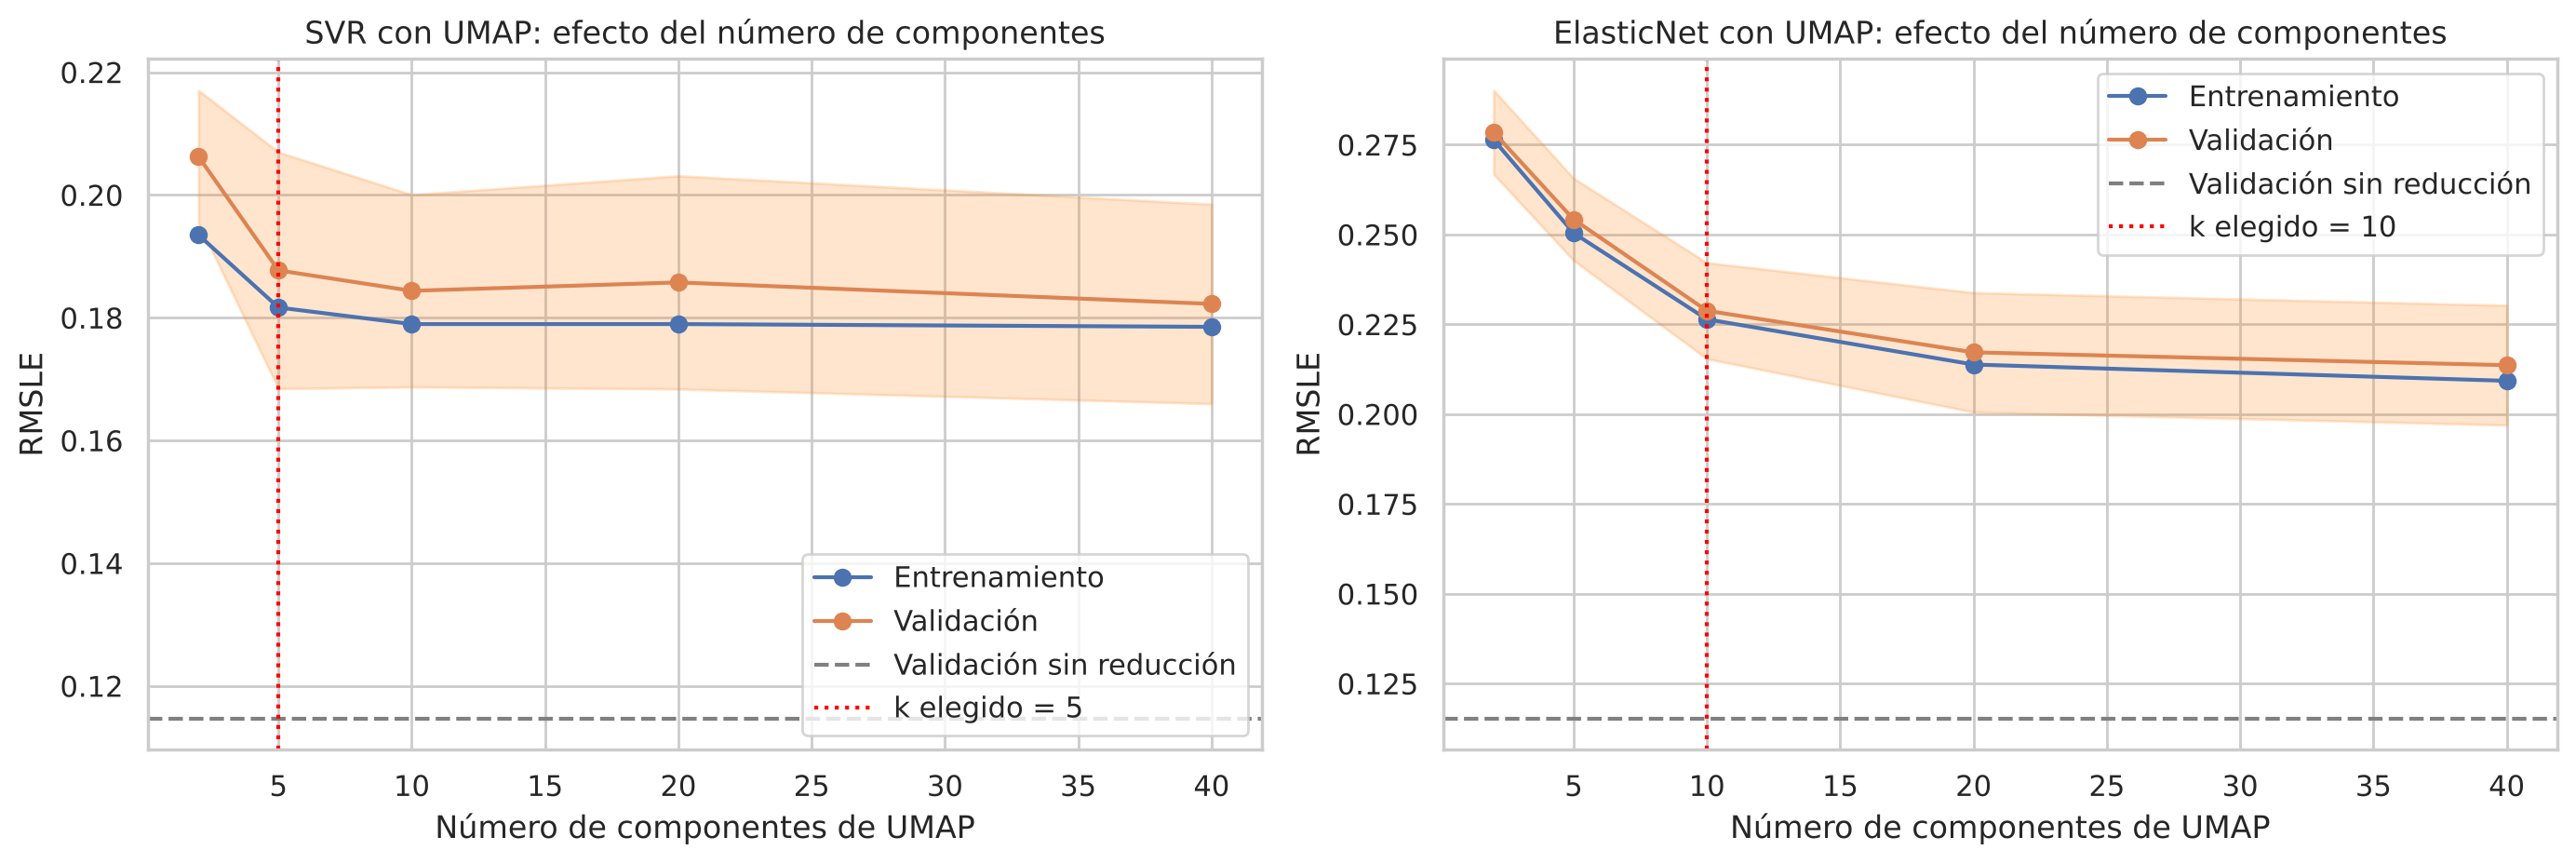

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for a, m in zip(ax, MODELOS):
    d = curva_umap[curva_umap["modelo"] == m]
    a.plot(d["k"], d["train"], "o-", label="Entrenamiento")
    a.plot(d["k"], d["val"], "o-", label="Validación")
    a.fill_between(d["k"], d["val"] - d["val_std"], d["val"] + d["val_std"], color="tab:orange", alpha=0.2)
    a.axhline(FILAS[m][0]["RMSLE_val"], color="gray", ls="--", label="Validación sin reducción")
    a.axvline(K_UMAP[m], color="red", ls=":", label=f"k elegido = {K_UMAP[m]}")
    a.set_xlabel("Número de componentes de UMAP")
    a.set_ylabel("RMSLE")
    a.set_title(f"{m} con UMAP: efecto del número de componentes")
    a.legend()
guardar("18_umap_componentes")

Nueva evaluación de los dos modelos con el número de componentes elegido (con la búsqueda en malla pequeña de hiperparámetros), incluyendo test.

In [ ]:
for m in MODELOS:
    fila, _ = evaluar(f"{m.lower()}_umap", f"{m} – UMAP ({K_UMAP[m]} comp.)",
                      pipe_de(m, reductor=umap_(K_UMAP[m])), MALLA_RED_UMAP[m])
    FILAS[m].append(fila)
    print(f"  {m}: mejores hiperparámetros con UMAP -> {fila['mejores_hiperparametros']}")

tabla([FILAS[m][i] for m in MODELOS for i in (0, 3)])

[svr_umap] cargado de results/red_svr_umap.pkl
  SVR: mejores hiperparámetros con UMAP -> {'C': 10, 'gamma': 0.1}
[elasticnet_umap] cargado de results/red_elasticnet_umap.pkl
  ElasticNet: mejores hiperparámetros con UMAP -> {'alpha': 0.001, 'l1_ratio': 0.1}


,Dimensiones,Reducción,RMSLE train,RMSLE val,RMSLE test,RMSE train,RMSE val,RMSE test,MAE train,MAE val,MAE test,R2 train,R2 val,R2 test
variante,,,,,,,,,,,,,,
SVR – original,287,0.0 %,0.0992 ± 0.0052,0.1147 ± 0.0211,0.1111 ± 0.0169,"17,138 ± 780","21,493 ± 4,951","20,056 ± 3,385","11,092 ± 360","13,780 ± 1,795","13,683 ± 1,608",0.953 ± 0.005,0.924 ± 0.033,0.937 ± 0.019
SVR – UMAP (5 comp.),5,98.3 %,0.1817 ± 0.0052,0.1877 ± 0.0267,0.1932 ± 0.0284,"40,205 ± 1,572","39,686 ± 4,789","38,470 ± 8,314","22,838 ± 315","24,341 ± 2,476","24,327 ± 3,471",0.742 ± 0.021,0.745 ± 0.035,0.769 ± 0.047
ElasticNet – original,326,0.0 %,0.0971 ± 0.0034,0.1153 ± 0.0157,0.1099 ± 0.0135,"17,390 ± 566","21,986 ± 5,282","20,584 ± 3,801","11,828 ± 224","14,050 ± 1,577","13,791 ± 1,682",0.952 ± 0.004,0.920 ± 0.035,0.934 ± 0.021
ElasticNet – UMAP (10 comp.),10,96.9 %,0.2264 ± 0.0127,0.2288 ± 0.0186,0.2444 ± 0.0289,"48,201 ± 2,851","47,900 ± 3,670","49,921 ± 10,349","29,917 ± 1,546","30,925 ± 2,091","32,246 ± 4,577",0.630 ± 0.028,0.627 ± 0.053,0.611 ± 0.064


Visualización de las viviendas de entrenamiento (codificación de SVR) en las 2 primeras componentes de PCA y en una proyección de UMAP a 2 dimensiones, coloreadas por precio. Ayuda a entender por qué una técnica conserva mejor la información del precio que la otra.

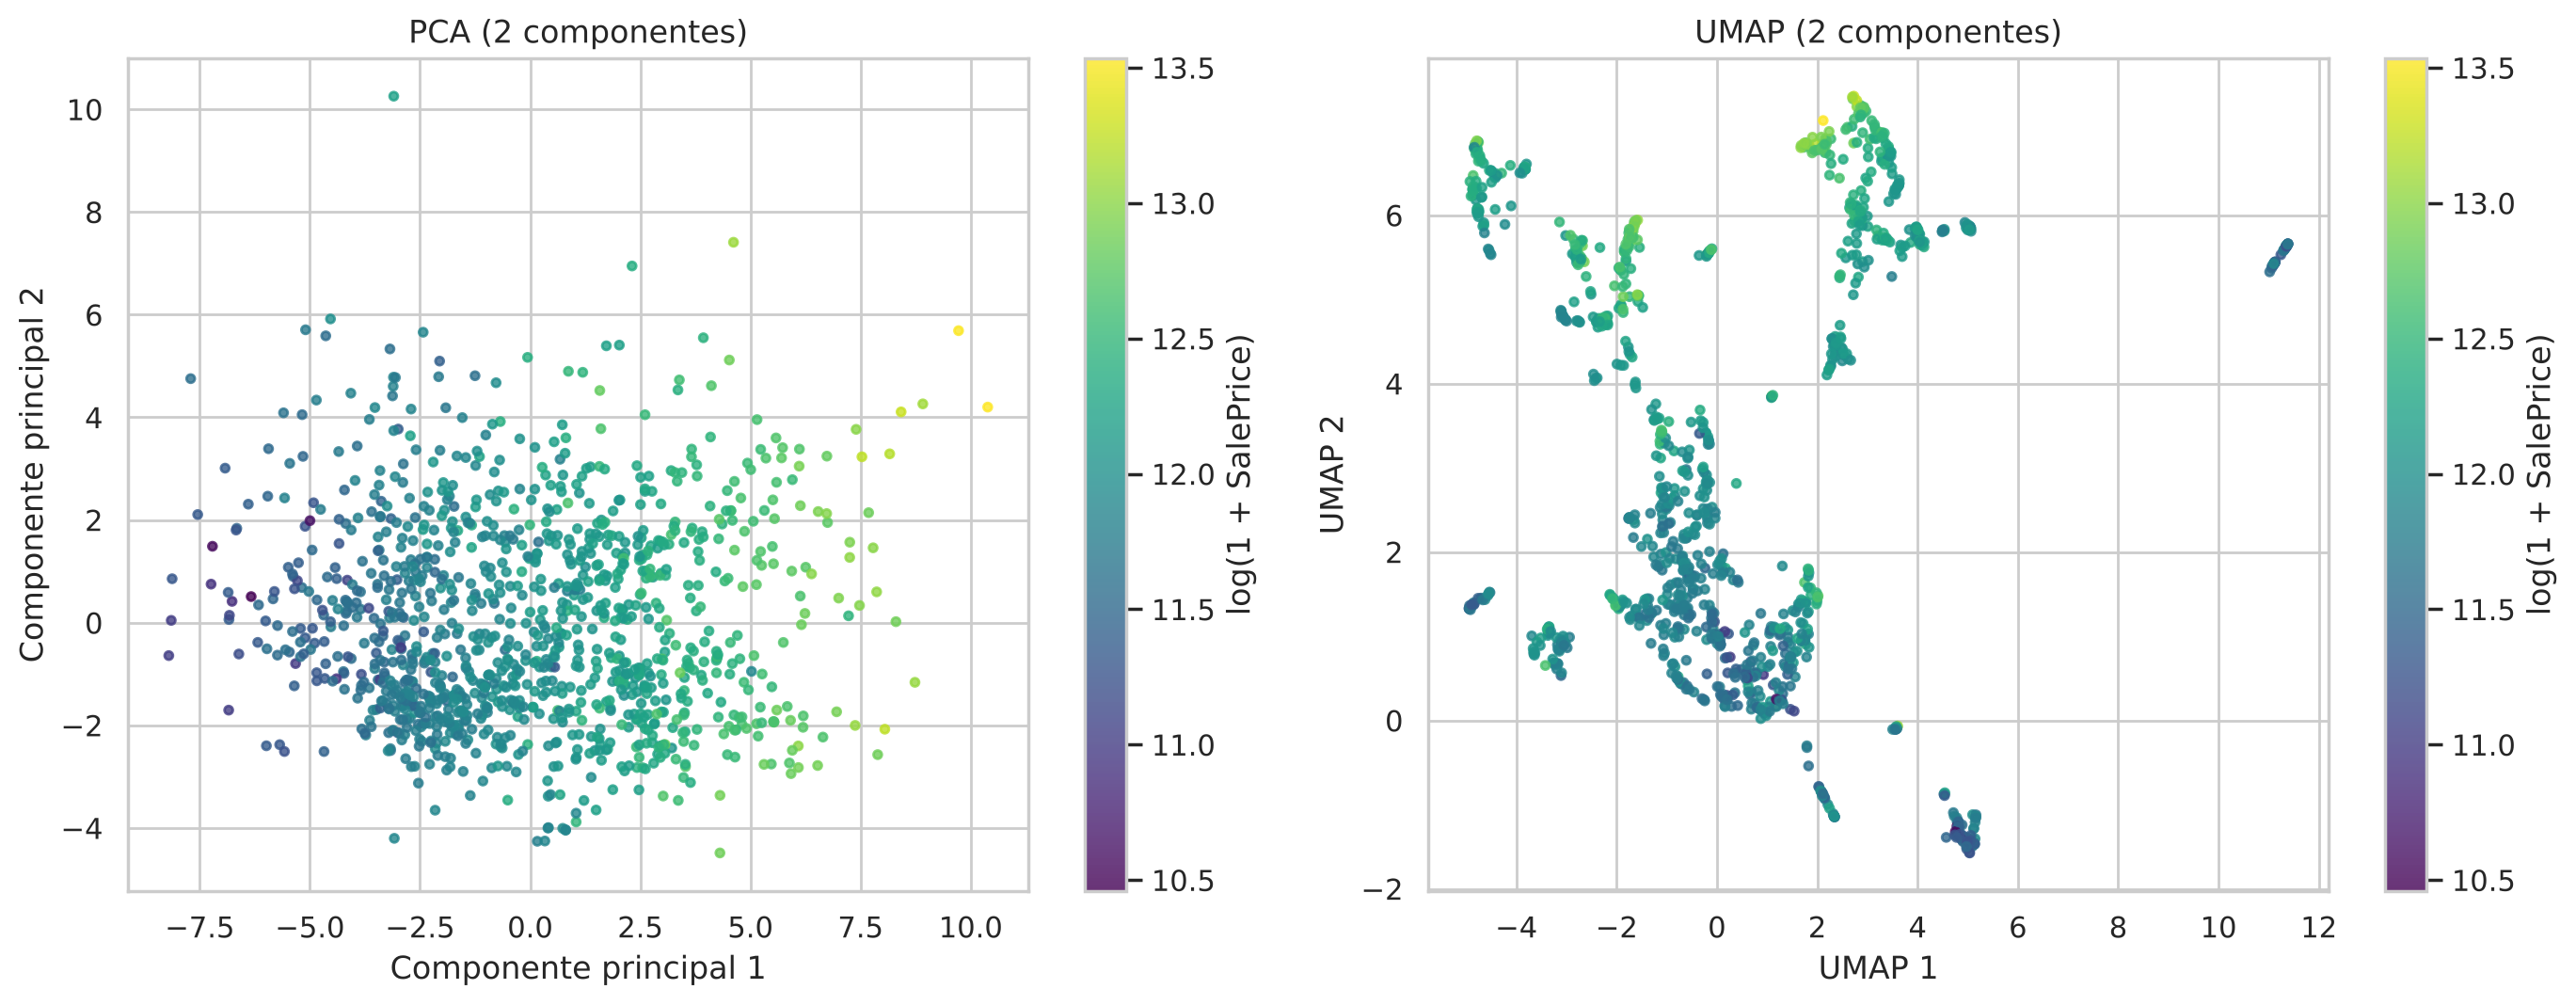

In [ ]:
Z_pca = PCA(n_components=2, random_state=SEED).fit_transform(XC["SVR"])
Z_umap = umap_(2).fit_transform(XC["SVR"])
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for a, Z, titulo, ejes in [(ax[0], Z_pca, "PCA (2 componentes)", ("Componente principal 1", "Componente principal 2")),
                           (ax[1], Z_umap, "UMAP (2 componentes)", ("UMAP 1", "UMAP 2"))]:
    sc = a.scatter(Z[:, 0], Z[:, 1], c=np.log1p(y_train), cmap="viridis", s=10, alpha=0.8)
    a.set_xlabel(ejes[0]); a.set_ylabel(ejes[1]); a.set_title(titulo)
    plt.colorbar(sc, ax=a, label="log(1 + SalePrice)")
guardar("19_proyecciones_2d")

## 4. Comparación final
Tabla con todas las variantes de los dos modelos: original, sin variables candidatas, PCA y UMAP. Incluye el número de dimensiones que recibe el modelo, el **porcentaje de reducción** respecto a las dimensiones originales de cada modelo y todas las métricas en entrenamiento, validación y test con su intervalo de confianza del 95 %. Se guarda en `results/tabla_reduccion_dimension.csv`.

In [ ]:
todas = FILAS["SVR"] + FILAS["ElasticNet"]
tabla_red = tabla(todas)
pd.DataFrame(todas).drop(columns="mejores_hiperparametros").to_csv("results/tabla_reduccion_dimension.csv", index=False)
tabla_red

,Dimensiones,Reducción,RMSLE train,RMSLE val,RMSLE test,RMSE train,RMSE val,RMSE test,MAE train,MAE val,MAE test,R2 train,R2 val,R2 test
variante,,,,,,,,,,,,,,
SVR – original,287,0.0 %,0.0992 ± 0.0052,0.1147 ± 0.0211,0.1111 ± 0.0169,"17,138 ± 780","21,493 ± 4,951","20,056 ± 3,385","11,092 ± 360","13,780 ± 1,795","13,683 ± 1,608",0.953 ± 0.005,0.924 ± 0.033,0.937 ± 0.019
SVR – sin candidatas,242,15.7 %,0.1026 ± 0.0051,0.1140 ± 0.0203,0.1129 ± 0.0164,"17,877 ± 795","20,895 ± 5,015","20,897 ± 3,663","11,539 ± 285","13,539 ± 1,839","14,147 ± 1,683",0.949 ± 0.005,0.928 ± 0.031,0.932 ± 0.021
SVR – PCA (80 comp.),80,72.1 %,0.1004 ± 0.0044,0.1187 ± 0.0169,0.1128 ± 0.0183,"17,172 ± 696","23,424 ± 4,446","20,553 ± 3,772","11,259 ± 229","14,431 ± 1,049","13,743 ± 1,703",0.953 ± 0.004,0.908 ± 0.040,0.934 ± 0.021
SVR – UMAP (5 comp.),5,98.3 %,0.1817 ± 0.0052,0.1877 ± 0.0267,0.1932 ± 0.0284,"40,205 ± 1,572","39,686 ± 4,789","38,470 ± 8,314","22,838 ± 315","24,341 ± 2,476","24,327 ± 3,471",0.742 ± 0.021,0.745 ± 0.035,0.769 ± 0.047
ElasticNet – original,326,0.0 %,0.0971 ± 0.0034,0.1153 ± 0.0157,0.1099 ± 0.0135,"17,390 ± 566","21,986 ± 5,282","20,584 ± 3,801","11,828 ± 224","14,050 ± 1,577","13,791 ± 1,682",0.952 ± 0.004,0.920 ± 0.035,0.934 ± 0.021
ElasticNet – sin candidatas,269,17.5 %,0.0997 ± 0.0033,0.1146 ± 0.0171,0.1102 ± 0.0132,"17,915 ± 633","22,075 ± 7,237","20,868 ± 3,835","12,074 ± 201","13,853 ± 2,048","13,914 ± 1,710",0.949 ± 0.004,0.918 ± 0.051,0.932 ± 0.022
ElasticNet – PCA (92 comp.),92,71.8 %,0.1074 ± 0.0039,0.1211 ± 0.0152,0.1128 ± 0.0149,"19,145 ± 599","22,536 ± 4,677","21,002 ± 3,575","13,153 ± 252","15,087 ± 1,370","14,154 ± 1,708",0.942 ± 0.004,0.917 ± 0.032,0.931 ± 0.023
ElasticNet – UMAP (10 comp.),10,96.9 %,0.2264 ± 0.0127,0.2288 ± 0.0186,0.2444 ± 0.0289,"48,201 ± 2,851","47,900 ± 3,670","49,921 ± 10,349","29,917 ± 1,546","30,925 ± 2,091","32,246 ± 4,577",0.630 ± 0.028,0.627 ± 0.053,0.611 ± 0.064


Gráfica comparativa del RMSLE de validación y test de cada variante, con su intervalo de confianza. La etiqueta de cada grupo indica el número de dimensiones.

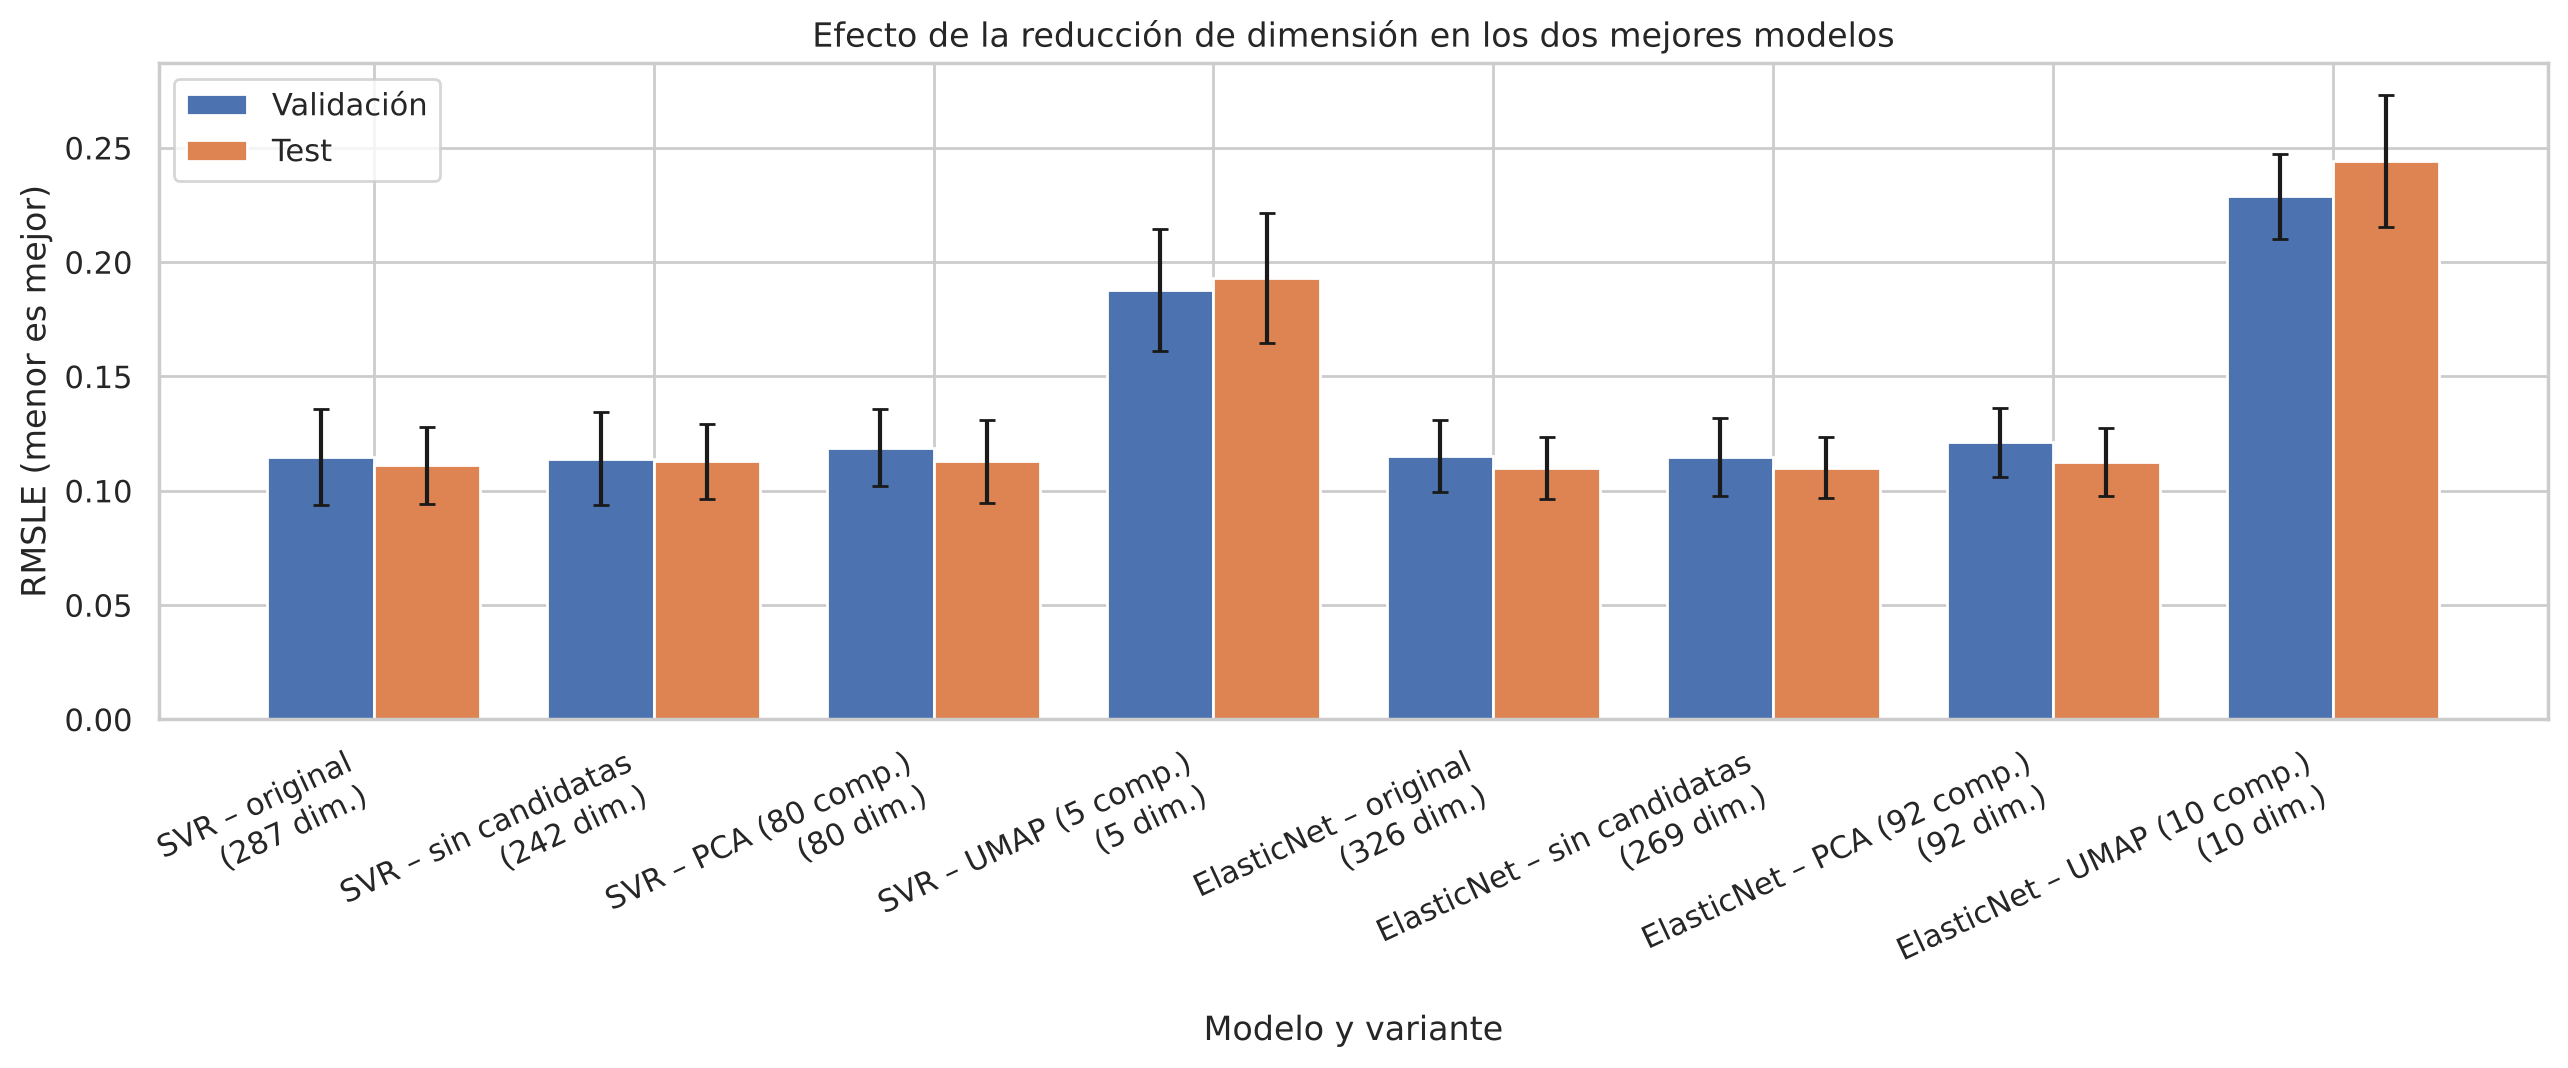

In [ ]:
t = pd.DataFrame(todas).set_index("variante")
x = np.arange(len(t))
fig, ax = plt.subplots(figsize=(13, 5.5))
for i, (fase, etiqueta) in enumerate([("val", "Validación"), ("test", "Test")]):
    ax.bar(x + (i - 0.5) * 0.38, t[f"RMSLE_{fase}"], 0.38, yerr=t[f"RMSLE_{fase}_IC"],
           capsize=3, label=etiqueta)
ax.set_xticks(x)
ax.set_xticklabels([f"{v}\n({d} dim.)" for v, d in zip(t.index, t["dimensiones"])], rotation=25, ha="right")
ax.set_xlabel("Modelo y variante")
ax.set_ylabel("RMSLE (menor es mejor)")
ax.set_title("Efecto de la reducción de dimensión en los dos mejores modelos")
ax.legend()
guardar("20_comparacion_reduccion")

### Consideraciones importantes de los resultados
- **Análisis individual:** las variables más relevantes coinciden con el análisis exploratorio (calidad general, barrio, área habitable, garaje, sótano). La comparación "original" vs "sin candidatas" indica si las variables de baja relevancia, casi constantes o redundantes aportan algo a los modelos.
- **PCA:** comparar el RMSLE con $k$ componentes contra el original. Si la diferencia está dentro de los intervalos de confianza, la reducción simplifica el modelo sin perder desempeño de forma significativa.
- **UMAP:** al ser no supervisado y enfocado en la estructura local, puede perder información relevante para el precio; la curva de componentes muestra cuánto.
- **Variables de calidad:** `OverallQual` y `ExterQual` están entre las más relevantes. No es fuga de información (se conocen al momento de la venta), pero hace que el problema sea más fácil de lo que parece; esto se discute en el informe.

Los valores concretos y las conclusiones se escriben en el informe a partir de las tablas y figuras de este notebook.